gf-data-profiling

Analysis plan

- get list of all topics (parsed) to see the most common over all time
- look at counts of top 5(?) over decades

In [22]:
# library imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [23]:
df = pd.read_csv("data/billboard.csv")
df.columns

Index(['song', 'artist', 'date', 'weeks_at_number_one', 'non_consecutive',
       'rating_1', 'rating_2', 'rating_3', 'overall_rating', 'divisiveness',
       ...
       'featured_in_a_then_contemporary_play', 'written_for_a_film',
       'featured_in_a_then_contemporary_film', 'written_for_a_t_v_show',
       'featured_in_a_then_contemporary_t_v_show', 'associated_with_dance',
       'topped_the_charts_by_multiple_artist', 'double_a_side',
       'eurovision_entry', 'u_s_artwork'],
      dtype='str', length=105)

parse lyrical topics into one list to look at total counts

In [24]:
df['year'] = df['date'].str[:4]
df['decade'] = (df['year'].astype(int) // 10) * 10

In [25]:
df_1 = df[:10]
df_1.shape

(10, 107)

In [26]:
all_time_topics_list = []
for cell in df["lyrical_topic"]:
    cell = str(cell)
    if ";" in cell:              # multiple topics
        cell = cell.split(";")
    else:                        # one topic
        cell = [cell]
    #print(cell)
    for top in cell:
        #print(top)
        all_time_topics_list.append(top)

all_time_topics_list = pd.Series(all_time_topics_list)
# overall most common topics
counts_all_time_topics = all_time_topics_list.value_counts()

In [27]:
print(counts_all_time_topics[0:5])
top_5_topics = ["Lust/Sex","Love","Lost Love","Longing for Love","Bad Relationships"]

Lust/Sex             271
Love                 269
Lost Love            252
Longing for Love     108
Bad Relationships     82
Name: count, dtype: int64


In [28]:
df_s = df[["song","lyrical_topic","decade"]]

create empty columns

In [29]:
df_s["Lust_Sex"] = None
df_s["Love"] = None
df_s["Lost_Love"] = None
df_s["Longing_for_Love"] = None
df_s["Bad_Relationships"] = None

add bools to columns for each song's lyrical topic

In [30]:
for i in range(len(df_s)):
    # lust/sex
    if "Lust/Sex" in str(df_s.iloc[i]["lyrical_topic"]):
        df_s.iloc[i,3] = True
    else:
        df_s.iloc[i,3] = False
    # love
    if "Love" in str(df_s.iloc[i]["lyrical_topic"]) and not "Lost Love" in str(df_s.iloc[i]["lyrical_topic"]) and not "Longing for Love" in str(df_s.iloc[i]["lyrical_topic"]):
        df_s.iloc[i,4] = True
    else:
        df_s.iloc[i,4] = False
    # lost love    
    if "Lost Love" in str(df_s.iloc[i]["lyrical_topic"]):
        df_s.iloc[i,5] = True
    else:
        df_s.iloc[i,5] = False
    # longing for love
    if "Longing for Love" in str(df_s.iloc[i]["lyrical_topic"]):
        df_s.iloc[i,6] = True
    else:
        df_s.iloc[i,6] = False
    # bad relationships
    if "Bad Relationships" in str(df_s.iloc[i]["lyrical_topic"]):
        df_s.iloc[i,7] = True
    else:
        df_s.iloc[i,7] = False
df_s.head()

,song,lyrical_topic,decade,Lust_Sex,Love,Lost_Love,Longing_for_Love,Bad_Relationships
0,Poor Little Fool,Lost Love,1950,False,False,True,False,False
1,Nel Blu Dipinto Di Blu,Flying;Dreaming,1950,False,False,False,False,False
2,Little Star,Longing for Love,1950,False,False,False,True,False
3,It's All in the Game,Love,1950,False,True,False,False,False
4,It's Only Make Believe,Lost Love,1950,False,False,True,False,False


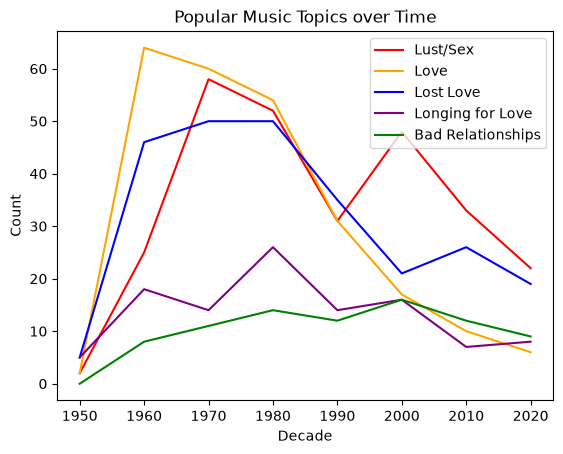

In [67]:
plot1 = sns.lineplot(df_s, x="decade", y="Lust_Sex", errorbar=None, estimator=sum, color="red", label="Lust/Sex")
plot1 = sns.lineplot(df_s, x="decade", y="Love", errorbar=None, estimator=sum, color="orange", label="Love")
plot3 = sns.lineplot(df_s, x="decade", y="Lost_Love", errorbar=None, estimator=sum, color="blue", label="Lost Love")
plot4 = sns.lineplot(df_s, x="decade", y="Longing_for_Love", errorbar=None, estimator=sum, color="purple", label="Longing for Love")
plot5 = sns.lineplot(df_s, x="decade", y="Bad_Relationships", errorbar=None, estimator=sum, color="green", label="Bad Relationships")
plt.xlabel("Decade")
plt.ylabel("Count")
plt.title("Popular Music Topics over Time")
plt.show()